In [ ]:
# 显示最后一个变量
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "last_expr"

# 中国八大核心城市地铁运营现状与效能对比分析报告

## 项目概述
- 数据来源：中国城市轨道交通协会《城市轨道交通2025年度统计和分析报告》、中国交通运输部每个月城市轨道交通运营数据速报、各大城市地铁官方网站运营数据报告、国家统计局《国民经济和社会发展统计公报》
- 分析目的：探索北上广深等8城地铁运营效能

## 数据处理
- 数据的整体情况
- 是否有缺失值
- 每个字段的含义

In [1]:
# 准备工作
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
## 设置中文显示
plt.rcParams["font.sans-serif"] = "SimHei"
plt.rcParams["axes.unicode_minus"] = False

In [2]:
# 显示所有变量
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

In [3]:
# 读入数据
yx = pd.read_csv("data/8城轨道交通运营数据_202501-202605.csv")
hx = pd.read_csv("data/8城核心数据_2025.csv")
yx.head()
hx.head()

,月份,城市,运营里程(km),客运量(万人次),进站量(万人次),客运强度(万人次/km·日),备注
0,Jan-25,北京,879.0,30215.6,16284.3,1.10,—
1,Feb-25,北京,879.0,28567.4,15345.6,1.04,—
2,Mar-25,北京,889.0,31234.5,16876.4,1.13,3月18日开通17号线北段（清河站—未来科学城北），新增10.0km
3,Apr-25,北京,889.0,30876.4,16676.5,1.12,—
4,May-25,北京,899.0,31567.8,17056.7,1.14,5月10日开通3号线东延（曹各庄北—管庄路西口），新增10.0km


,城市,占地面积(km²),建成区面积(km²),常住人口(万人),建成区常住人口(万人),数据年份说明
0,北京,16410.5,1599.0,2183.2,1912,面积2025；人口2024
1,上海,6340.5,1242.0,2480.3,2189,面积2025；人口2024
2,广州,7434.4,1431.8,1897.8,1682,面积2025；人口2024
3,成都,14335.0,1059.6,2147.4,1720,面积2025；人口2024
4,深圳,1997.5,962.0,1799.0,1744,面积2025；人口2024


### 运营数据字段
- 月份：一共有17个月（2025年1月到2026年5月）
- 城市：一共有八个城市（北京、上海、广州、深圳、重庆、成都、杭州、武汉）
- 运营里程：地铁线路一共的里程
- 客运量：当前月份的运输服务次数（完成了多少人次的位移服务）
- 进站量：当前月份的进站人数
- 客运强度：当前月份每一公里轨道上平均承担了多少客流量（客运强度=运营里程/客运量）
- 备注：当前月份有无新的线路开通或旧的线路关停

### 核心数据字段
- 城市：八个城市（北京、上海、广州、深圳、重庆、成都、杭州、武汉）
- 占地面积：八个城市对应的占地
- 建成区面积：城市面积（非山地田野）
- 常住人口：长期居住的人口数
- 数据年份说明：面具数据来自2025，人口数据来自2024

In [4]:
# 数据基本信息
yx.info()
hx.info()

<class 'pandas.DataFrame'>
RangeIndex: 136 entries, 0 to 135
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   月份              136 non-null    str    
 1   城市              136 non-null    str    
 2   运营里程(km)        136 non-null    float64
 3   客运量(万人次)        136 non-null    float64
 4   进站量(万人次)        136 non-null    float64
 5   客运强度(万人次/km·日)  136 non-null    float64
 6   备注              136 non-null    str    
dtypes: float64(4), str(3)
memory usage: 7.6 KB
<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   城市           8 non-null      str    
 1   占地面积(km²)    8 non-null      float64
 2   建成区面积(km²)   8 non-null      float64
 3   常住人口(万人)     8 non-null      float64
 4   建成区常住人口(万人)  8 non-null      int64  
 5   数据年份说明       8 non-null      str    
dtypes: float64(3), int64(1),

### 数据信息
- 无缺失值

## 数据预处理
- 在核心数据中加入人口密度和建成区地铁线路密度

In [5]:
# 新增"最新运营里程(km)"列
latest_mileage = yx.groupby('城市')['运营里程(km)'].last().reset_index()
latest_mileage.columns = ['城市', '最新运营里程(km)']
hx = hx.merge(latest_mileage, on='城市', how='left')

# 新增"建成区地铁线路密度(km/km²)"列
hx['建成区地铁线路密度(km/km²)'] = hx['最新运营里程(km)'] / hx['建成区面积(km²)']

# 新增"人口密度(万人/km²)"列
hx['人口密度(万人/km²)'] = hx['建成区常住人口(万人)'] / hx['建成区面积(km²)']

In [6]:
# 检查
hx.head()

,城市,占地面积(km²),建成区面积(km²),常住人口(万人),建成区常住人口(万人),数据年份说明,最新运营里程(km),建成区地铁线路密度(km/km²),人口密度(万人/km²)
0,北京,16410.5,1599.0,2183.2,1912,面积2025；人口2024,929.0,0.580988,1.195747
1,上海,6340.5,1242.0,2480.3,2189,面积2025；人口2024,881.5,0.709742,1.762480
2,广州,7434.4,1431.8,1897.8,1682,面积2025；人口2024,772.6,0.539601,1.174745
3,成都,14335.0,1059.6,2147.4,1720,面积2025；人口2024,719.5,0.679030,1.623254
4,深圳,1997.5,962.0,1799.0,1744,面积2025；人口2024,634.5,0.659563,1.812890


- 删除数据年份说明列

In [7]:
# 删除数据年份说明列
hx = hx.drop(columns=['数据年份说明'])

In [8]:
#检查
hx.head()

,城市,占地面积(km²),建成区面积(km²),常住人口(万人),建成区常住人口(万人),最新运营里程(km),建成区地铁线路密度(km/km²),人口密度(万人/km²)
0,北京,16410.5,1599.0,2183.2,1912,929.0,0.580988,1.195747
1,上海,6340.5,1242.0,2480.3,2189,881.5,0.709742,1.762480
2,广州,7434.4,1431.8,1897.8,1682,772.6,0.539601,1.174745
3,成都,14335.0,1059.6,2147.4,1720,719.5,0.679030,1.623254
4,深圳,1997.5,962.0,1799.0,1744,634.5,0.659563,1.812890


### 数据转换
- 运营数据的月份是字符串，转成date形式

In [9]:
# 将 '月份' 列转为 datetime 类型
yx['月份'] = pd.to_datetime(yx['月份'], format='%b-%y')

In [10]:
# 检查
yx.info()
yx.head()

<class 'pandas.DataFrame'>
RangeIndex: 136 entries, 0 to 135
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   月份              136 non-null    datetime64[us]
 1   城市              136 non-null    str           
 2   运营里程(km)        136 non-null    float64       
 3   客运量(万人次)        136 non-null    float64       
 4   进站量(万人次)        136 non-null    float64       
 5   客运强度(万人次/km·日)  136 non-null    float64       
 6   备注              136 non-null    str           
dtypes: datetime64[us](1), float64(4), str(2)
memory usage: 7.6 KB


,月份,城市,运营里程(km),客运量(万人次),进站量(万人次),客运强度(万人次/km·日),备注
0,2025-01-01,北京,879.0,30215.6,16284.3,1.10,—
1,2025-02-01,北京,879.0,28567.4,15345.6,1.04,—
2,2025-03-01,北京,889.0,31234.5,16876.4,1.13,3月18日开通17号线北段（清河站—未来科学城北），新增10.0km
3,2025-04-01,北京,889.0,30876.4,16676.5,1.12,—
4,2025-05-01,北京,899.0,31567.8,17056.7,1.14,5月10日开通3号线东延（曹各庄北—管庄路西口），新增10.0km


- 但是我们取值的数据是按月份，所以改为Period形式

In [11]:
# 将 datetime 转为 Period[M]（月度周期类型）
yx['月份'] = yx['月份'].dt.to_period('M')

In [12]:
# 检查
yx.info()
yx.head()

<class 'pandas.DataFrame'>
RangeIndex: 136 entries, 0 to 135
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype    
---  ------          --------------  -----    
 0   月份              136 non-null    period[M]
 1   城市              136 non-null    str      
 2   运营里程(km)        136 non-null    float64  
 3   客运量(万人次)        136 non-null    float64  
 4   进站量(万人次)        136 non-null    float64  
 5   客运强度(万人次/km·日)  136 non-null    float64  
 6   备注              136 non-null    str      
dtypes: float64(4), period[M](1), str(2)
memory usage: 7.6 KB


,月份,城市,运营里程(km),客运量(万人次),进站量(万人次),客运强度(万人次/km·日),备注
0,2025-01,北京,879.0,30215.6,16284.3,1.10,—
1,2025-02,北京,879.0,28567.4,15345.6,1.04,—
2,2025-03,北京,889.0,31234.5,16876.4,1.13,3月18日开通17号线北段（清河站—未来科学城北），新增10.0km
3,2025-04,北京,889.0,30876.4,16676.5,1.12,—
4,2025-05,北京,899.0,31567.8,17056.7,1.14,5月10日开通3号线东延（曹各庄北—管庄路西口），新增10.0km


- 在核心数据中添加客流量和客运强度的均值

In [13]:
# 基于 yx 计算各城市平均值
city_avg = (
    yx.groupby('城市')[['客运量(万人次)', '客运强度(万人次/km·日)']]
      .mean()
      .round(4)                # 保留4位小数，按需调整
      .reset_index()
      .rename(columns={
          '客运量': '平均客运量(万人次)',
          '客运强度': '平均客运强度(万人次/km·日)'
      })
)

# 合并到 hx（以"城市"为关联键）
hx = hx.merge(city_avg, on='城市', how='left')

In [14]:
#检查
hx.head()

,城市,占地面积(km²),建成区面积(km²),常住人口(万人),建成区常住人口(万人),最新运营里程(km),建成区地铁线路密度(km/km²),人口密度(万人/km²),客运量(万人次),客运强度(万人次/km·日)
0,北京,16410.5,1599.0,2183.2,1912,929.0,0.580988,1.195747,30627.6118,1.0912
1,上海,6340.5,1242.0,2480.3,2189,881.5,0.709742,1.762480,31710.5235,1.1647
2,广州,7434.4,1431.8,1897.8,1682,772.6,0.539601,1.174745,28676.6941,1.2635
3,成都,14335.0,1059.6,2147.4,1720,719.5,0.679030,1.623254,19713.0824,0.9541
4,深圳,1997.5,962.0,1799.0,1744,634.5,0.659563,1.812890,29263.7353,1.5212


## 数据保存

In [ ]:
yx.to_csv('./data/8城轨道交通运营数据_clear.csv', index=False, encoding='utf-8-sig')
hx.to_csv('./data/8城核心数据_clear.csv', index=False, encoding='utf-8-sig')

## 数据分析

### 各个城市地铁线路图

<img src="./img/北京地铁线路图.jpg" alt="北京地铁线路图" width="600">
<img src="./img/上海地铁线路图.jpg" alt="上海地铁线路图" width="600">
<img src="./img/广州地铁线路图.png" alt="广州地铁线路图" width="600">
<img src="./img/深圳地铁线路图.png" alt="深圳地铁线路图" width="600">
<img src="./img/杭州地铁线路图.jpeg" alt="杭州地铁线路图" width="600">
<img src="./img/成都地铁线路图.png" alt="成都地铁线路图" width="600">
<img src="./img/武汉地铁线路图.jpg" alt="武汉地铁线路图" width="600">
<img src="./img/重庆地铁线路图.png" alt="重庆地铁线路图" width="600">

### 规模与效率的静态格局分析
- 将城市按“运营里程”和“客流强度”两个维度划分为四象限（高规模高效率、高规模低效率、低规模高效率、低规模低效率）
- 深圳是否稳居“小而强”？
- 成都、重庆是否陷入“大而弱”的规模陷阱？
- 北京、上海作为超大城市，其效率是否已触及天花板？

In [15]:
# 准备工作
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
## 设置中文显示
plt.rcParams["font.sans-serif"] = "SimHei"
plt.rcParams["axes.unicode_minus"] = False

In [23]:
# 读取数据
hx = pd.read_csv("data/8城核心数据_clear.csv")
yx = pd.read_csv("data/8城轨道交通运营数据_clear.csv")
hx.head()
yx.head()

,月份,城市,运营里程(km),客运量(万人次),进站量(万人次),客运强度(万人次/km·日),备注
0,2025-01,北京,879.0,30215.6,16284.3,1.10,—
1,2025-02,北京,879.0,28567.4,15345.6,1.04,—
2,2025-03,北京,889.0,31234.5,16876.4,1.13,3月18日开通17号线北段（清河站—未来科学城北），新增10.0km
3,2025-04,北京,889.0,30876.4,16676.5,1.12,—
4,2025-05,北京,899.0,31567.8,17056.7,1.14,5月10日开通3号线东延（曹各庄北—管庄路西口），新增10.0km


- 先计算中位数，再按中位数划分出高规模高效率、高规模低效率、低规模高效率、低规模低效率

In [24]:
# 计算中位数
median_licheng = hx["最新运营里程(km)"].median()
median_keyunqiangdu = hx["客运强度(万人次/km·日)"].median()
median_licheng
median_keyunqiangdu

np.float64(1.02265)

In [25]:
# 按中位数划分四象限
def classify_quadrant(row):
    high_scale = row["最新运营里程(km)"] >= median_licheng
    high_efficiency = row["客运强度(万人次/km·日)"] >= median_keyunqiangdu
    
    if high_scale and high_efficiency:
        return '高规模高效率'
    elif not high_scale and high_efficiency:
        return '低规模高效率'
    elif not high_scale and not high_efficiency:
        return '低规模低效率'
    else:
        return '高规模低效率'

hx['象限'] = hx.apply(classify_quadrant, axis=1)

# 打印分类结果验证
print("===== 四象限分类结果 =====")
for q in ['高规模高效率', '低规模高效率', '高规模低效率', '低规模低效率']:
    cities = hx[hx['象限'] == q]['城市'].tolist()
    print(f"{q}: {cities}")

===== 四象限分类结果 =====
高规模高效率: ['北京', '上海', '广州']
低规模高效率: ['深圳']
高规模低效率: ['成都']
低规模低效率: ['武汉', '杭州', '重庆']


- 按分类画散点图

In [26]:
# 显示最后一个变量
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "last_expr"

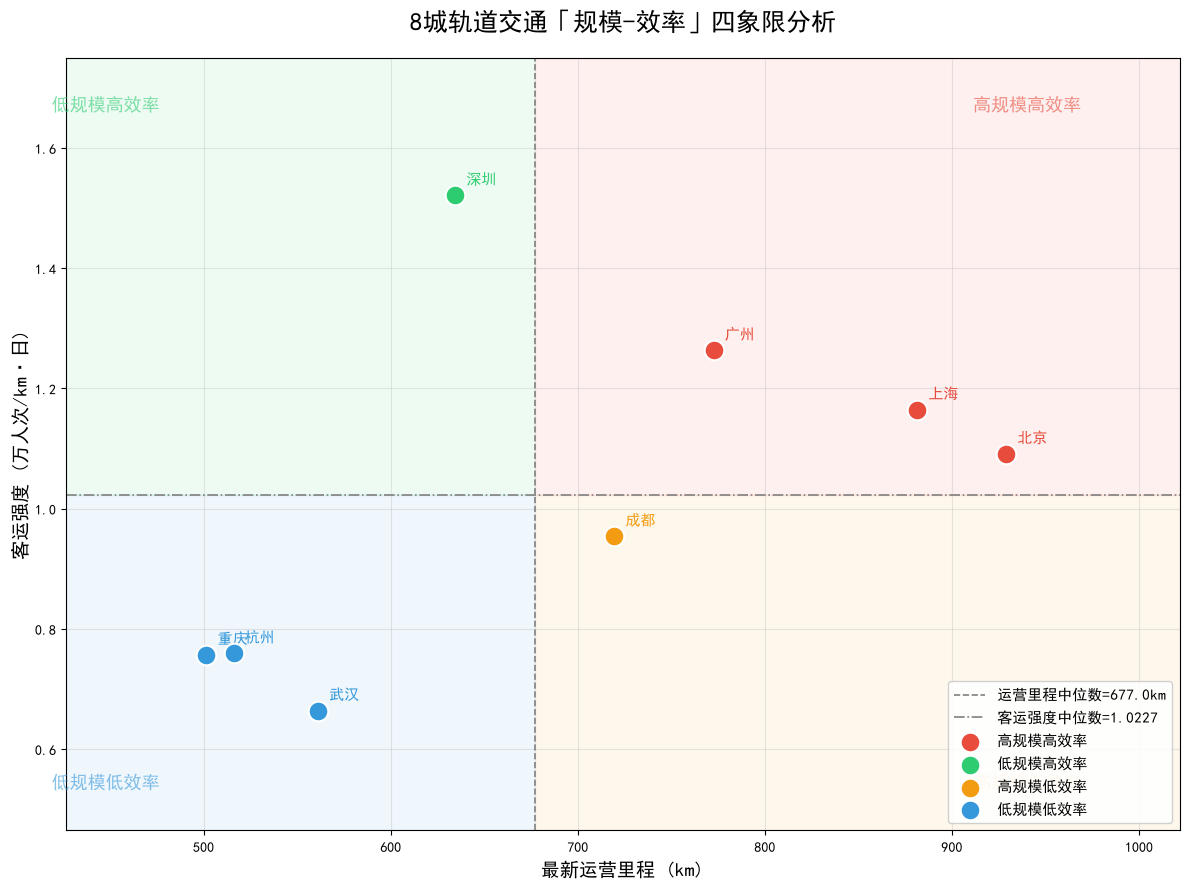

In [27]:
color_map = {
    '高规模高效率': '#E74C3C',   # 红
    '低规模高效率': '#2ECC71',   # 绿
    '高规模低效率': '#F39C12',   # 橙
    '低规模低效率': '#3498DB'    # 蓝
}

fig, ax = plt.subplots(figsize=(12, 9))

# 坐标轴范围（留白避免标注被裁切）
x_min = hx["最新运营里程(km)"].min() * 0.85
x_max = hx["最新运营里程(km)"].max() * 1.1
y_min = hx["客运强度(万人次/km·日)"].min() * 0.7
y_max = hx["客运强度(万人次/km·日)"].max() * 1.15

# 绘制四象限背景色块
x_ratio = (median_licheng - x_min) / (x_max - x_min)
ax.axhspan(y_min, median_keyunqiangdu, xmin=0, xmax=x_ratio, color='#3498DB', alpha=0.08)
ax.axhspan(median_keyunqiangdu, y_max, xmin=0, xmax=x_ratio, color='#2ECC71', alpha=0.08)
ax.axhspan(y_min, median_keyunqiangdu, xmin=x_ratio, xmax=1, color='#F39C12', alpha=0.08)
ax.axhspan(median_keyunqiangdu, y_max, xmin=x_ratio, xmax=1, color='#E74C3C', alpha=0.08)

# 中位数分界线
ax.axvline(x=median_licheng, color='gray', linestyle='--', linewidth=1.2,
           label=f'运营里程中位数={median_licheng:.1f}km')
ax.axhline(y=median_keyunqiangdu, color='gray', linestyle='-.', linewidth=1.2,
           label=f'客运强度中位数={median_keyunqiangdu:.4f}')

# 按象限绘制散点并标注城市名
for quadrant, color in color_map.items():
    subset = hx[hx['象限'] == quadrant]
    ax.scatter(subset["最新运营里程(km)"], subset["客运强度(万人次/km·日)"],
               c=color, s=200, edgecolors='white', linewidth=1.5,
               zorder=5, label=quadrant)
    for _, row in subset.iterrows():
        ax.annotate(row['城市'],
                    (row["最新运营里程(km)"], row["客运强度(万人次/km·日)"]),
                    textcoords="offset points", xytext=(8, 8),
                    fontsize=11, fontweight='bold', color=color)

# 象限文字标签
label_positions = [
    (x_max * 0.92, y_max * 0.95, '高规模高效率', '#E74C3C'),
    (x_min * 1.05, y_max * 0.95, '低规模高效率', '#2ECC71'),
    (x_max * 0.92, y_min * 1.15, '高规模低效率', '#F39C12'),
    (x_min * 1.05, y_min * 1.15, '低规模低效率', '#3498DB'),
]
for xp, yp, text, tc in label_positions:
    ax.text(xp, yp, text, fontsize=13, fontweight='bold', color=tc, alpha=0.6, ha='center')

# 图表美化
ax.set_xlabel('最新运营里程 (km)', fontsize=14)
ax.set_ylabel('客运强度 (万人次/km·日)', fontsize=14)
ax.set_title('8城轨道交通「规模-效率」四象限分析', fontsize=18, fontweight='bold', pad=20)
ax.legend(loc='lower right', fontsize=11, framealpha=0.9)
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
# plt.savefig('8城规模效率四象限.png', dpi=150, bbox_inches='tight')

### 轨道交通“规模-效率”四象限分析结论
- 基于运营里程中位数（677.0 km）与客运强度中位数（1.0227 万人次/km·日）的划分，8城静态格局呈现出显著的分异特征，具体分析结论如下：
    1. **深圳稳居“小而强”标杆，效率断层领先**
       - 深圳是唯一落入低规模高效率象限的城市。其运营里程低于中位数，但客运强度远超1.0227的中位线，在8城中形成绝对优势。这验证了深圳依托极高建成区人口密度与紧凑城市形态，实现了轨道网络的高效集约利用。“小”是阶段性规模状态，“强”则是结构性效率优势，且随着后续线路开通，其规模仍有向上跃升空间，而效率基本盘依然稳固。
    3. **成都呈现“大而弱”特征，需警惕规模陷阱**
        - 成都是唯一落入高规模低效率象限的城市。其运营里程超过中位数，线网规模位居前列，但客运强度未达中位水平，反映出线网扩张速度超前于客流培育节奏。这一格局提示成都已进入“规模-效率”再平衡的关键窗口期，后续发展重心应从增量扩张转向存量提质，通过优化线网结构、强化TOD开发来激活既有线路效能，避免陷入低效路径依赖。
    5. **重庆并非“大而弱”，实为“小且弱”的特殊样本**
        - 重庆运营里程与客运强度均低于中位数，归入低规模低效率象限。这与公众认知中的“大城市”印象存在偏差，本质上是由山地地形制约导致的建设成本高、覆盖难度大所致。结合其超3000万常住人口基数，当前线网规模仍显不足，尚未达到“规模过剩”的陷阱阶段，反而处于规模亟待补强的发展期。其低效率更多是地理条件约束下的阶段性结果，而非规划失当。
    7. **京沪效率未触顶，但已转入高位平台期**
        - 北京、上海与广州共同构成高规模高效率象限，证明超大城市在庞大线网基础上仍可维持高效运营。但京沪客运强度与深圳、广州存在明显差距，表明其效率提升已从“增量驱动”切换至“存量优化”模式。外围延伸线路拉长平均运距、多中心格局下通勤距离增加等因素，使得单纯新增里程对整体强度的边际贡献递减。未来突破天花板的路径不在于继续铺摊子，而在于快线加密、市域铁路融合及换乘效率提升等结构性优化。